# Traveling Salesman Problem via Row Generation (Subtour Elimination)

## Overview

We solve the TSP using **row generation**: we iteratively solve a relaxed MIP and add **subtour elimination constraints (SECs)** until the solution forms a single cycle.

We model the TSP over **undirected edges** $\{i,j\}$ in the Euclidean plane. 

### Master Problem

At each iteration we solve:

$$
\begin{aligned}
\min \quad & \sum_{\{i,j\} \in E} d_{ij}\, x_{ij} \\
\text{s.t.} \quad & \sum_{j \neq i} x_{\{i,j\}} = 2 & \forall\, i \in V \quad & (\text{two edges touch each node}) \\
& \sum_{\{i,j\} \subseteq S} x_{ij} \leq |S| - 1 & \forall\, S \subsetneq V,\; 2 \leq |S| \leq |V|-1 \quad & (\text{SECs, added lazily}) \\
& x_{ij} \in \{0, 1\} & \forall\, \{i,j\} \in E
\end{aligned}
$$

where $E = \{\{i,j\} : i < j\}$ is the set of all undirected edges.

### Row Generation Loop

| Step | Action |
|------|---------|
| **Solve** | Solve the master MIP with all constraints added so far |
| **Detect** | Find all (undirected) subtours — connected components — in the optimal solution |
| **Feasible?** | If there is exactly one tour visiting all nodes → **STOP** |
| **Cut** | For every subtour $S$ detected, add SEC $\sum_{\{i,j\}\subseteq S} x_{ij} \leq |S|-1$ |
| **Repeat** | Go back to Solve |

Because each SEC rules out at least one infeasible subtour and the number of possible subtours is finite, the algorithm terminates in a finite number of iterations.

In [1]:
# ── Dependencies ──────────────────────────────────────────────────────────────
# pip install pyomo highspy numpy matplotlib  (or: poetry install)
%load_ext autoreload
%autoreload 2

import numpy as np
import time
import warnings
warnings.filterwarnings('ignore')

import pyomo.environ as pyo

try:
    import highspy
except ImportError:
    raise ImportError("Install highspy:  pip install highspy")

try:
    solver_test = pyo.SolverFactory('appsi_highs')
    print(f"Pyomo appsi_highs solver available: {solver_test.available()}")
except Exception as e:
    raise ImportError(f"Pyomo appsi_highs not available: {e}")

from helpers import euclidean_distance_matrix, plot_iteration_grid
from tsp_helpers import (
    build_master_problem, extract_solution, find_subtours, tour_length,
    plot_instance, plot_iteration, plot_final_tour, plot_convergence,
)

Pyomo appsi_highs solver available: True


## 1. Problem Instance

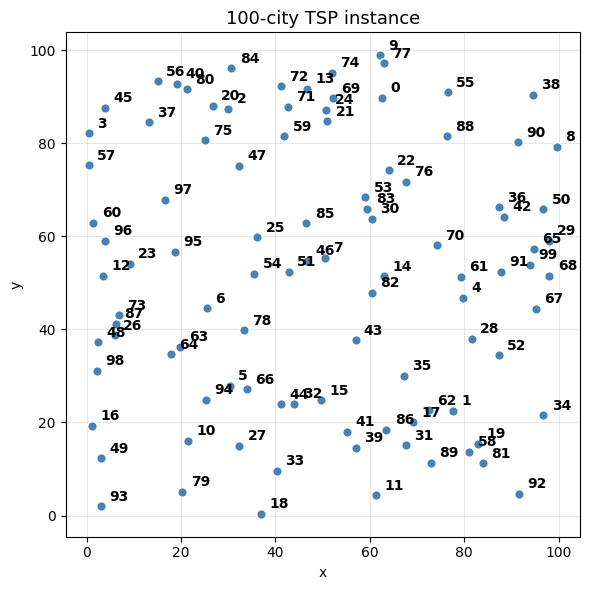

Cities: 100   |   Undirected edges: 4950


In [2]:
# ── Generate a small-to-medium TSP instance ───────────────────────────────────
rng = np.random.default_rng(seed=7)
N = 100                                         # number of cities
coords = rng.uniform(0, 100, size=(N, 2))        # (x, y) coordinates

D = euclidean_distance_matrix(coords)            # D[i,j] = distance between i and j
np.fill_diagonal(D, np.inf)                      # no self-loops

# Edge set — undirected, each pair counted once (i < j)
EDGES = [(i, j) for i in range(N) for j in range(N) if i < j]

plot_instance(coords)
print(f"Cities: {N}   |   Undirected edges: {len(EDGES)}")

## 2. Master Problem

We model the master MIP in Pyomo with **undirected binary edge variables** $x_{ij}$, $i < j$. We keep a **growing list of SEC cuts** `sec_cuts` — each entry is a `frozenset` of node indices forming a subtour, and the corresponding constraint is:

$$\sum_{\substack{\{i,j\} \in E \\ i \in S,\, j \in S}} x_{ij} \leq |S| - 1$$

A single degree constraint per node replaces the former pair of in/out-degree constraints:

$$\sum_{j \neq i} x_{\{i,j\}} = 2 \qquad \forall\, i \in V$$

*Implementation:* `build_master_problem` in [`tsp_helpers.py`](tsp_helpers.py).

## 3. Subtour Detection

Given a binary solution $\{x^*_{ij}\}$, the degree constraints guarantee that every node has exactly **two** active edges. The solution graph is therefore a **disjoint union of undirected cycles**. We find these cycles by building an undirected adjacency list and tracing each connected component in order.

*Implementation:* `extract_solution`, `find_subtours` and `tour_length` in [`tsp_helpers.py`](tsp_helpers.py).

## 4. Visualization Helpers

`plot_iteration`, `plot_final_tour` and `plot_convergence` live in [`tsp_helpers.py`](tsp_helpers.py); `plot_iteration_grid` lives in [`helpers.py`](helpers.py).

## 5. Row Generation Algorithm

We iterate until the undirected solution graph consists of a single cycle (all $N$ nodes in one connected component of degree 2).

In [3]:
# ── Solver setup ──────────────────────────────────────────────────────────────
solver = pyo.SolverFactory('appsi_highs')
solver.options['mip_rel_gap'] = 1e-6
solver.options['log_to_console'] = False    # suppress HiGHS banner

# ── Row generation state ──────────────────────────────────────────────────────
sec_cuts:   list[frozenset] = []   # accumulated SEC cuts
history:    list[dict]      = []   # store per-iteration data for later analysis

MAX_ITER = 200
t_start  = time.perf_counter()

print(f"{'Iter':>5}  {'Obj':>12}  {'#Subtours':>10}  {'#SECs':>7}  {'Time(s)':>8}")
print("-" * 50)

for iteration in range(1, MAX_ITER + 1):

    # ── Solve master MIP ──────────────────────────────────────────────────────
    model = build_master_problem(N, D, EDGES, sec_cuts)
    result = solver.solve(model)

    if result.solver.termination_condition not in (
        pyo.TerminationCondition.optimal,
        pyo.TerminationCondition.feasible,
    ):
        print(f"Solver failed at iteration {iteration}: {result.solver.termination_condition}")
        break

    # ── Extract solution ──────────────────────────────────────────────────────
    x_vals   = extract_solution(model, EDGES)
    obj_val  = pyo.value(model.obj)
    subtours = find_subtours(x_vals, N)
    elapsed  = time.perf_counter() - t_start

    print(f"{iteration:>5}  {obj_val:>12.4f}  {len(subtours):>10}  {len(sec_cuts):>7}  {elapsed:>8.3f}")

    # ── Store history ─────────────────────────────────────────────────────────
    history.append({
        "iteration":  iteration,
        "obj":        obj_val,
        "n_subtours": len(subtours),
        "n_cuts":     len(sec_cuts),
        "x_vals":     x_vals.copy(),
        "subtours":   [list(s) for s in subtours],
    })

    # ── Termination check ─────────────────────────────────────────────────────
    if len(subtours) == 1:          # single tour → optimality
        print(f"\n✓ Optimal tour found after {iteration} iteration(s).")
        print(f"  Total distance : {obj_val:.4f}")
        print(f"  SECs added     : {len(sec_cuts)}")
        print(f"  Wall time      : {elapsed:.3f}s")
        break

    # ── Add SECs for every proper subtour detected ────────────────────────────
    new_cuts = 0
    for subtour in subtours:
        S = frozenset(subtour)
        if len(S) < N:              # skip if it already spans all nodes
            sec_cuts.append(S)
            new_cuts += 1
    if new_cuts == 0:
        print("No new cuts generated — terminating.")
        break

else:
    print(f"Warning: reached maximum iterations ({MAX_ITER}) without finding a tour.")

 Iter           Obj   #Subtours    #SECs   Time(s)
--------------------------------------------------


    1      788.2626          14        0     0.856


    2      806.0533           7       14     1.355


    3      808.8662           3       21     1.968


    4      809.8001           3       24     2.630


    5      810.3084           3       27     3.370


    6      812.9090           1       30     4.517

✓ Optimal tour found after 6 iteration(s).
  Total distance : 812.9090
  SECs added     : 30
  Wall time      : 4.517s


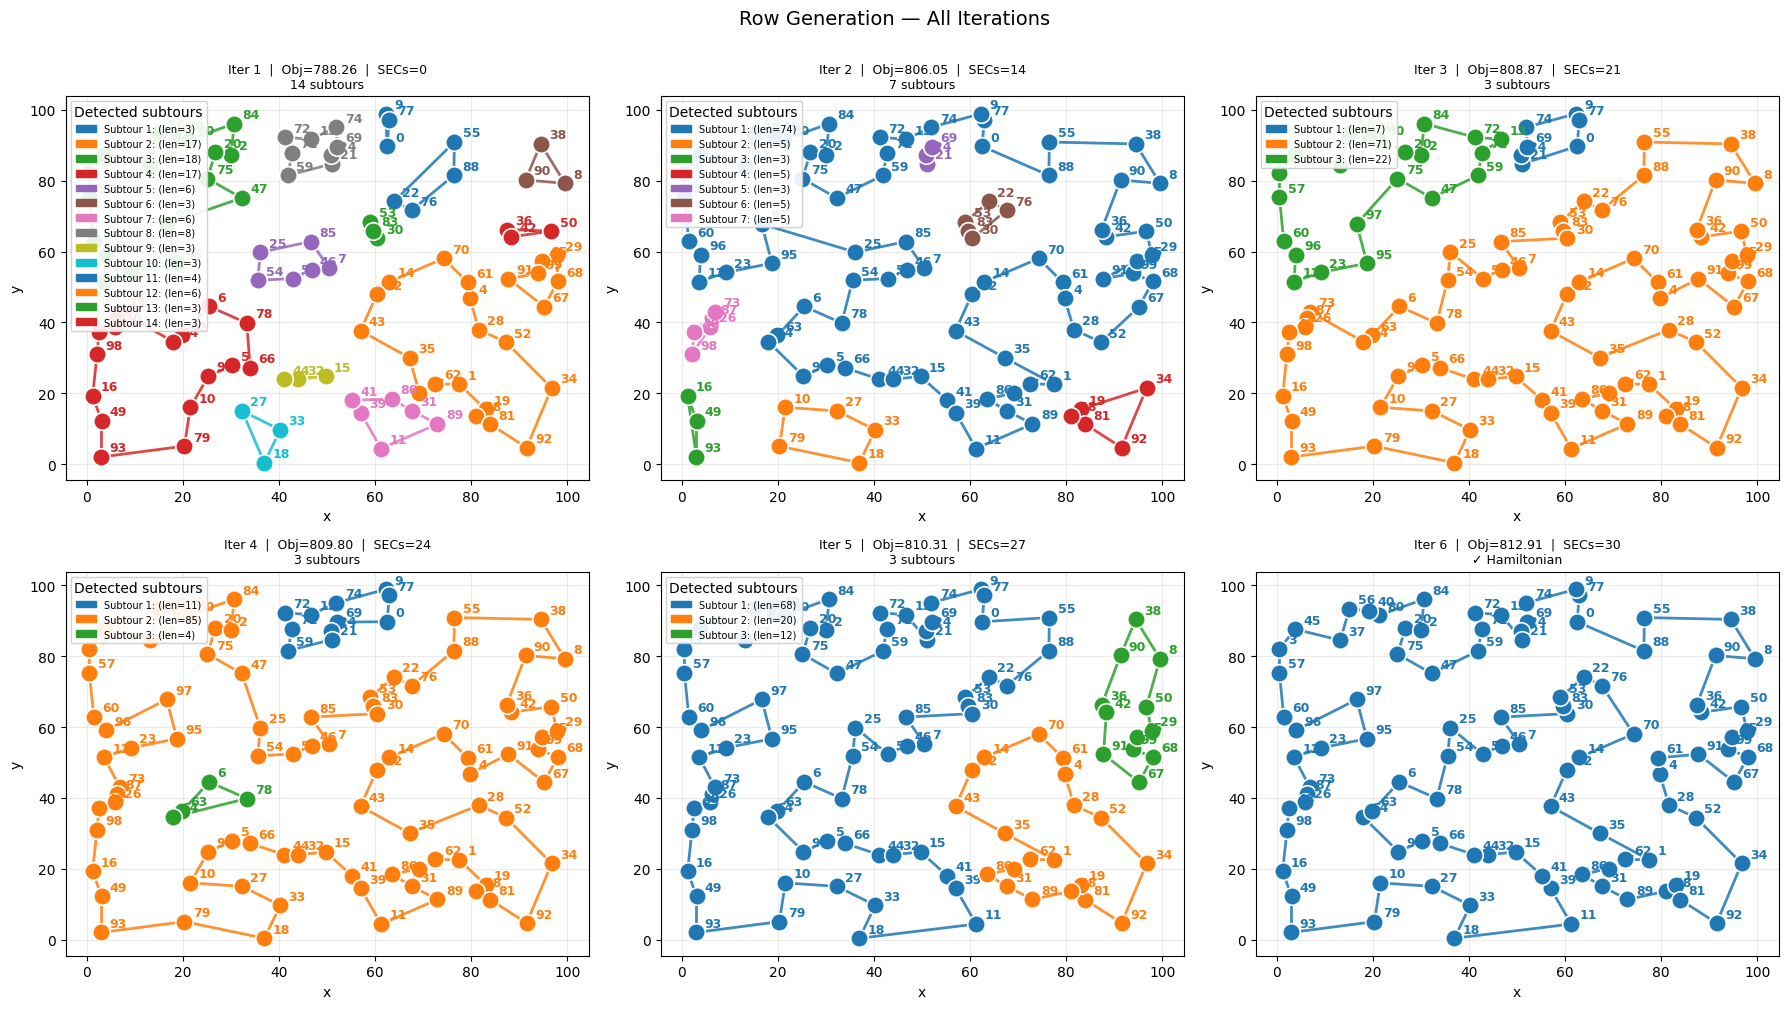

In [4]:
# ── Plot all iterations in a 3-column grid ────────────────────────────────────
plot_iteration_grid(
    history,
    lambda h, ax: plot_iteration(
        coords    = coords,
        x_vals    = h["x_vals"],
        subtours  = h["subtours"],
        iteration = h["iteration"],
        obj_val   = h["obj"],
        n_cuts    = h["n_cuts"],
        ax        = ax,
    ),
    title="Row Generation — All Iterations",
)

## 6. Final Optimal Tour

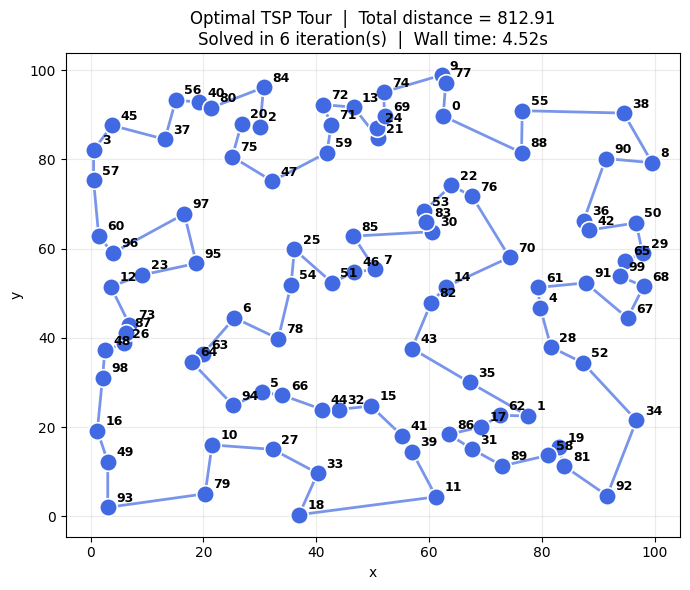

In [5]:
# ── Plot the final optimal tour ───────────────────────────────────────────────
final = history[-1]
plot_final_tour(
    coords      = coords,
    x_vals      = final["x_vals"],
    obj_val     = final["obj"],
    n_iterations= final["iteration"],
    elapsed     = elapsed,
)

## 7. Convergence Analysis

We visualize three things across iterations:
1. **Objective value** 
2. **Number of subtours**
3. **Cumulative SECs added**

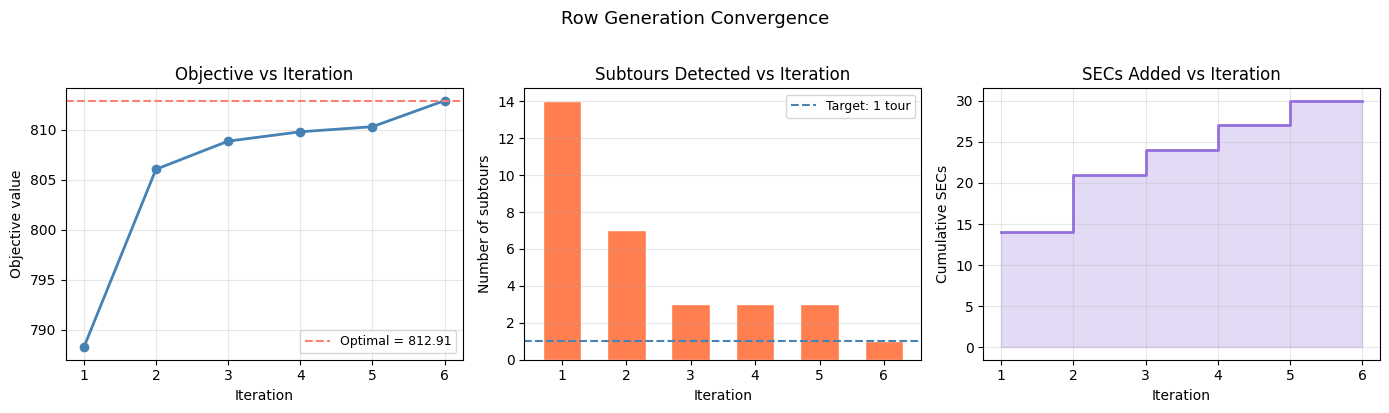

In [6]:
plot_convergence(history)